<a href="https://colab.research.google.com/github/QuinnGeary/Sonoma-County-Animal-Shelter-Data-Evaluation/blob/main/sonoma_shelter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Road A Stray Walks



#### Quinn Geary, Angel Soliven, Viridiana Ramos Ayala, Alexander Trujillo

## Introduction

The following is an in-depth examination of data and statistics pulled from a database for the Sonoma County Animal Shelter. The information provided in this report is intended for shareholders of the Sonoma County Animal Shelter to brief them on the outcomes of animals who enter the shelter as strays.

Through the manipulation and visualization of the dataset, shareholders will be able to see ten stray specific statistics, which are:

*   Where do the most stray animals come from?
*   Where would they likely end up?
*   What is a stray animal's outcome most likely to be?
*   How long do stray animals stay in the shelter?
*   How does the sterilization status of the animals who enter as strays affect length of stay?
*   What is the health status of the stray animals upon intake?
*   What are the most common outcome types per stray animal type?
*   Does size influence adoption rates of stray animals?
*   What are the average ages of stray animals when they were taken in?
*   How does intake type vary from animal type?

To answer these questions, the dataset used was collected from the SoCo Data website. The dataset in question is the Animal Shelter Intake and Outcome dataset, specifically the state of the data on October 13th, 2025. It was collected by exporting through the CSV file format.

Primary variables for our examination include:

*   Type: Type of animal
*   Sex: Male, Female, Neutered Male, Spayed Female
*   Date of Birth: Approximate date of birth
*   Intake Date: Date animal was taken into the shelter
*   Outcome Date: Date animal left the shelter
*   Days in Shelter: Number of days the animal was in the shelter
*   Intake Type: Reason for intake
*   Outcome Type: Reason for release from shelter
*   Intake Condition: Animal's condition at intake
*   Intake Jurisdiction: Jurisdiction responsible for animal intake
*   Outcome Jurisdiction: Area animal went to
*   Size: Large, medium, small, toy

## Initial Data Exploration

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Read shelter data

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/grbruns/cst383/master/sonoma-shelter-13-october-2025.csv')

Before processing, the dataframe contains these columns.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31774 entries, 0 to 31773
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Name                  23393 non-null  object 
 1   Type                  31774 non-null  object 
 2   Breed                 31774 non-null  object 
 3   Color                 31774 non-null  object 
 4   Sex                   31774 non-null  object 
 5   Size                  31738 non-null  object 
 6   Date Of Birth         24086 non-null  object 
 7   Impound Number        31774 non-null  object 
 8   Kennel Number         31766 non-null  object 
 9   Animal ID             31774 non-null  object 
 10  Intake Date           31774 non-null  object 
 11  Outcome Date          31557 non-null  object 
 12  Days in Shelter       31774 non-null  object 
 13  Intake Type           31774 non-null  object 
 14  Intake Subtype        31774 non-null  object 
 15  Outcome Type       

A sample of each column from 5 random rows.

In [ ]:
df.sample(5)

,Name,Type,Breed,Color,Sex,Size,Date Of Birth,Impound Number,Kennel Number,Animal ID,...,Intake Subtype,Outcome Type,Outcome Subtype,Intake Condition,Outcome Condition,Intake Jurisdiction,Outcome Jurisdiction,Outcome Zip Code,Location,Count
3096,LOLA,DOG,PIT BULL,BROWN,Spayed,LARGE,07/16/2012,K18-028267,DS71,A372565,...,FLD_ARREST,RETURN TO OWNER,OVER THE COUNTER_PRVS,HEALTHY,HEALTHY,SANTA ROSA,OUT OF COUNTY,94720.0,"(37.8739847, -122.2571591)",1
11706,NaN,CAT,DOMESTIC SH,BLACK,Unknown,KITTN,NaN,K17-023586,RECEIVING,A353164,...,OVER THE COUNTER,EUTHANIZE,UNDERAGEWT,TREATABLE/MANAGEABLE,TREATABLE/MANAGEABLE,COUNTY,NaN,NaN,NaN,1
26603,CHAS,DOG,GERM SHEPHERD,BLACK/TAN,Male,LARGE,11/17/2009,K14-010581,DS85,A284968,...,PRIV_SHELT,TRANSFER,B A GERMAN,HEALTHY,HEALTHY,SANTA ROSA,COUNTY,95403.0,"(38.4716444, -122.7398255)",1
21745,ROXY,DOG,SAMOYED/SIBERIAN HUSKY,WHITE/BLACK,Spayed,LARGE,08/08/2016,K17-024565,DA09,A355975,...,FIELD,ADOPTION,MOB EVENT,HEALTHY,HEALTHY,COUNTY,COUNTY,95409.0,"(38.46382, -122.67058)",1
8678,HARLEY,CAT,DOMESTIC LH,BRN TABBY,Neutered,KITTN,05/06/2015,K15-016177,LOBBY,A327799,...,OVER THE COUNTER,ADOPTION,WALKIN,HEALTHY,HEALTHY,SANTA ROSA,SANTA ROSA,95403.0,"(38.4716444, -122.7398255)",1


Shape of dataset

In [ ]:
df.shape

(31774, 24)

Basic descriptive data statistics

In [ ]:
df.describe()

,Outcome Zip Code,Count
count,27192.000000,31774.000000
mean,95042.270631,0.993989
std,3586.217127,0.077300
min,1922.000000,0.000000
25%,95401.000000,1.000000
50%,95404.000000,1.000000
75%,95425.000000,1.000000
max,99701.000000,1.000000


Columns Intake Date, Date of Birth, and Outcome Date are converted to allow for calculations.

In [ ]:
df['Date Of Birth'] = pd.to_datetime(df['Date Of Birth'])
df['Intake Date'] = pd.to_datetime(df['Intake Date'])
df['Outcome Date'] = pd.to_datetime(df['Outcome Date'])

Find the eldest animal

In [ ]:
oldestanimal = df['Date Of Birth'].min()
print(f"The oldest animal in the shelter was born on {oldestanimal}")

The oldest animal in the shelter was born on 1989-03-04 00:00:00


A new column with the animals ages.

In [ ]:
df['age'] = (df['Intake Date'] - df['Date Of Birth']).dt.days / 365.25
df['age']

,age
0,NaN
1,NaN
2,1.998631
3,0.906229
4,2.576318
...,...
31769,0.125941
31770,7.646817
31771,4.000000
31772,1.481177


In [ ]:
df['age'].dropna()
df['age']

,age
0,NaN
1,NaN
2,1.998631
3,0.906229
4,2.576318
...,...
31769,0.125941
31770,7.646817
31771,4.000000
31772,1.481177


Counts for every type of animal; A look into the Type variable

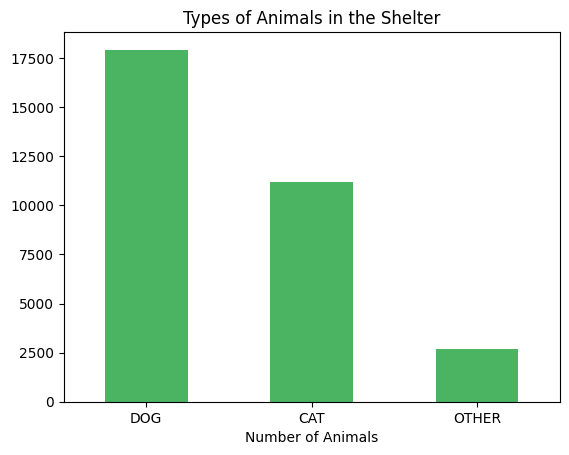

In [ ]:
(df['Type'].value_counts()).plot.bar(color='#4BB462', rot=0);
plt.xlabel("Number of Animals")
plt.title("Types of Animals in the Shelter");

Animal counts per intake type (log10); A look into the Intake Type variable

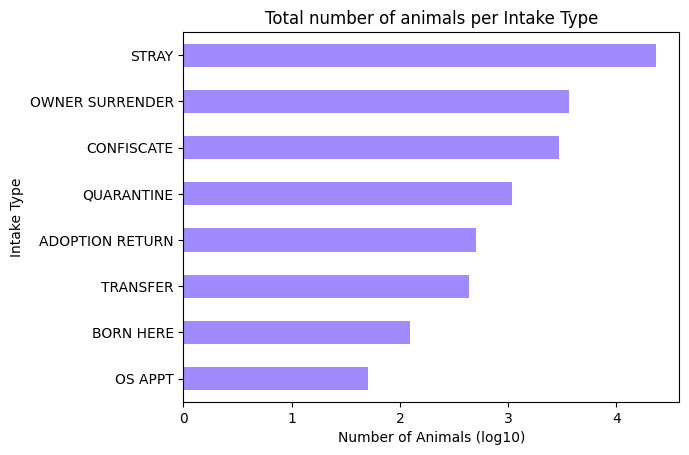

In [ ]:
np.log10(df['Intake Type'].value_counts().sort_values()).plot.barh(color='#A18AFF')
plt.title('Total number of animals per Intake Type')
plt.xlabel('Number of Animals (log10)')
plt.show()

Total number of animals per outcome type; A look into the Outcome Type variable by Type

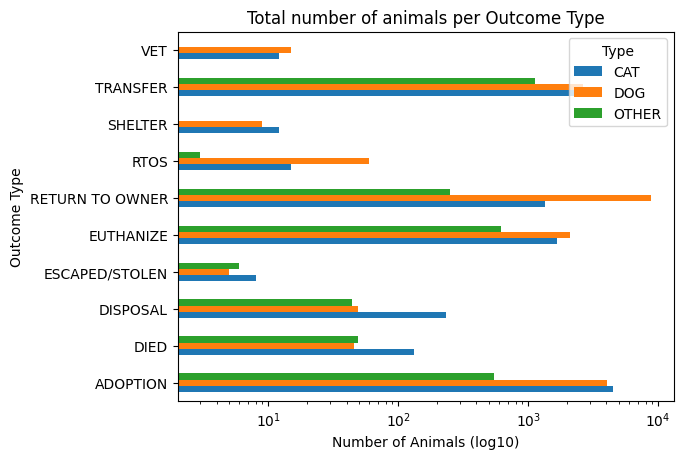

In [ ]:
pd.crosstab(df['Outcome Type'], df['Type']).plot.barh(logx=True) #avoid division by zero
plt.title('Total number of animals per Outcome Type')
plt.xlabel('Number of Animals (log10)');

Animal counts for sterilization/sex of the animal; A look into the Sex variable by Type

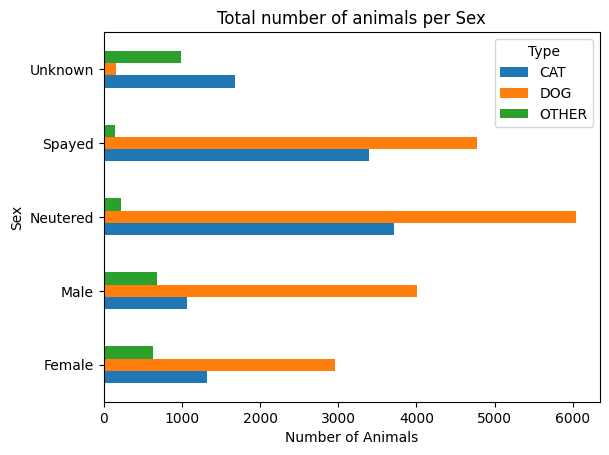

In [ ]:
pd.crosstab(df['Sex'],df['Type']).plot.barh();
plt.title('Total number of animals per Sex');
plt.xlabel('Number of Animals');

Animal counts for each Intake Condition of the animal; A look into the Intake Condition variable

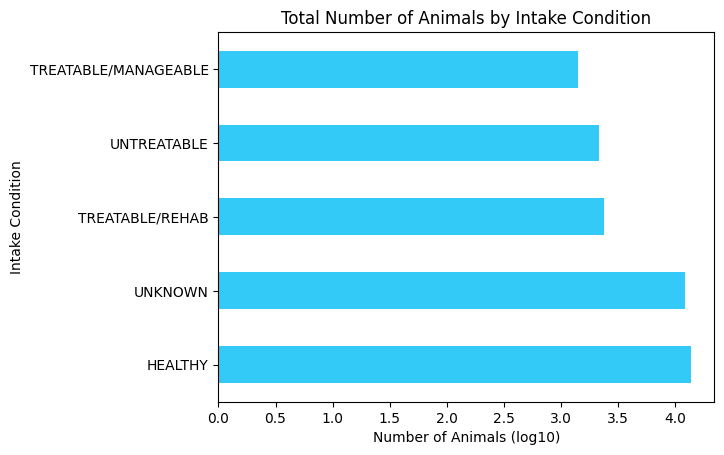

In [ ]:
np.log10(df['Intake Condition'].value_counts()).plot.barh(title='Total Number of Animals by Intake Condition', color='#33CAF8')
plt.xlabel('Number of Animals (log10)');

Animal counts for each Outcome Condition; A look into the Outcome Condition variable

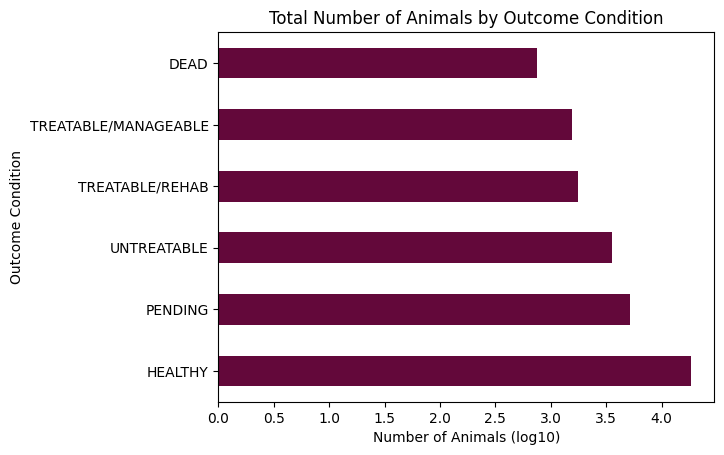

In [ ]:
np.log10(df['Outcome Condition'].value_counts()).plot.barh(title='Total Number of Animals by Outcome Condition', color='#63083A')
plt.xlabel('Number of Animals (log10)');

Animal counts for each Intake Jurisdiction (log10); A look into the Intake Jurisdiction variable

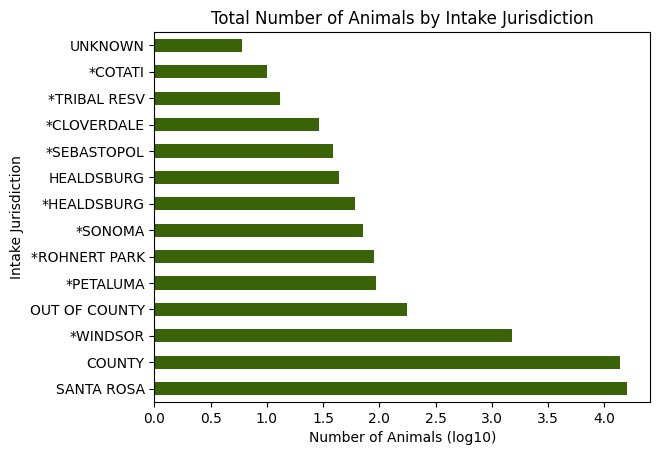

In [ ]:
np.log10(df['Intake Jurisdiction'].value_counts()).plot.barh(title='Total Number of Animals by Intake Jurisdiction', color='#3A6308')
plt.xlabel('Number of Animals (log10)');

Animal counts for each Outcome Jurisdiction (log10); A look into the Outcome Jurisdiction variable

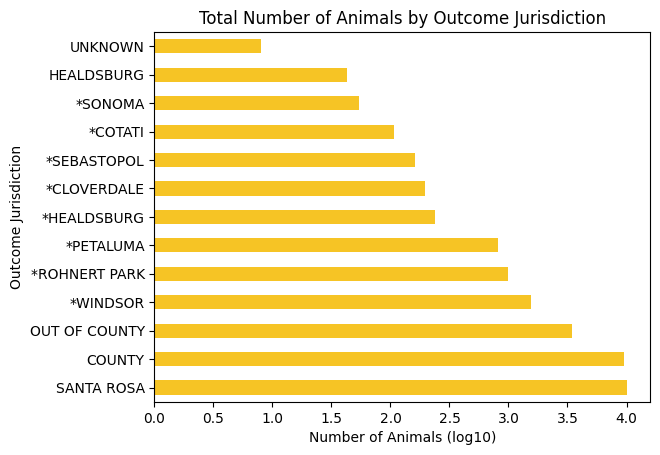

In [ ]:
np.log10(df['Outcome Jurisdiction'].value_counts()).plot.barh(title='Total Number of Animals by Outcome Jurisdiction', color='#F6C425')
plt.xlabel('Number of Animals (log10)');

Animal counts for each Size (log10); A look into the Size variable

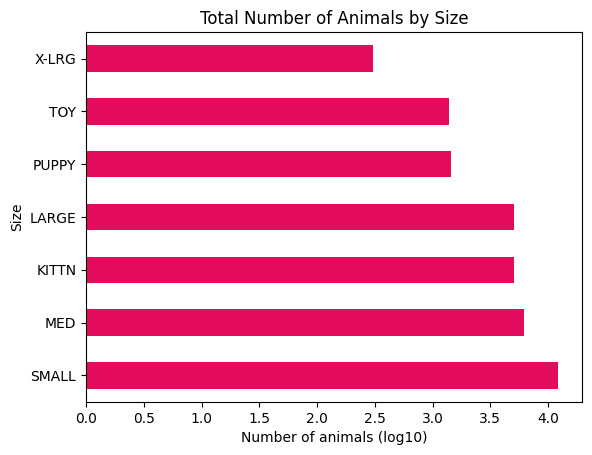

In [ ]:
np.log10(df['Size'].value_counts()).plot.barh(title='Total Number of Animals by Size', color='#E30B5C')
plt.xlabel('Number of animals (log10)');

## Data preprocessing

Non-essential and unused columns are dropped.

In [ ]:
df = df.drop(['Name', 'Color', 'Animal ID', 'Kennel Number', 'Impound Number', 'Outcome Zip Code', 'Location'], axis=1)

Columns that are the incorrect data type for mathemetical operations are converted to float data-types.

In [ ]:
df['Days in Shelter'] = pd.to_numeric(df['Days in Shelter'], errors='coerce')
df['Days in Shelter'].dtype


dtype('float64')

Statistics showing the days in shelter

In [ ]:
df['Days in Shelter'].agg(['mean', 'median', 'min', 'max']).round(2)

,Days in Shelter
mean,20.45
median,9.00
min,0.00
max,891.00


The processed data frame now appears as.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31774 entries, 0 to 31773
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Type                  31774 non-null  object        
 1   Breed                 31774 non-null  object        
 2   Sex                   31774 non-null  object        
 3   Size                  31738 non-null  object        
 4   Date Of Birth         24086 non-null  datetime64[ns]
 5   Intake Date           31774 non-null  datetime64[ns]
 6   Outcome Date          31557 non-null  datetime64[ns]
 7   Days in Shelter       31772 non-null  float64       
 8   Intake Type           31774 non-null  object        
 9   Intake Subtype        31774 non-null  object        
 10  Outcome Type          31551 non-null  object        
 11  Outcome Subtype       31206 non-null  object        
 12  Intake Condition      31774 non-null  object        
 13  Outcome Conditio

Continous Variable avg days is created by taken the mean of the Days in Shelter Column.

In [ ]:
avgdays = df['Days in Shelter'].mean()
print(f"On average the amount of days spent in the shelter is {avgdays:.1f} days")

On average the amount of days spent in the shelter is 20.4 days


Continuous variable deathrate is created.

In [ ]:
deathrate = (df["Outcome Type"].isin(["DIED", "EUTHANIZE", "DISPOSAL"]).sum() / len(df))
print(f" The death rate is: {deathrate:.2%}")

 The death rate is: 15.57%


Continuous variable survivalrate is created.

In [ ]:
survivalrate = (df["Outcome Type"].isin(["RETURN TO OWNER", "ADOPTION", "TRANSFER", "RTOS", "VET", "SHELTER", "ESCAPED/STOLEN"]).sum() / len(df))
print(f"The survival rate is: {survivalrate:.2%}")

The survival rate is: 83.73%


## Data exploration and visualization

#1. Where do the most stray animals come from?

To understand the geographic distribution of our shelter's intake, we need to identify which jurisdictions bring in the highest number of stray animals. This can help shareholders allocate resources or target community neuter programs more effectively in high-intake areas.


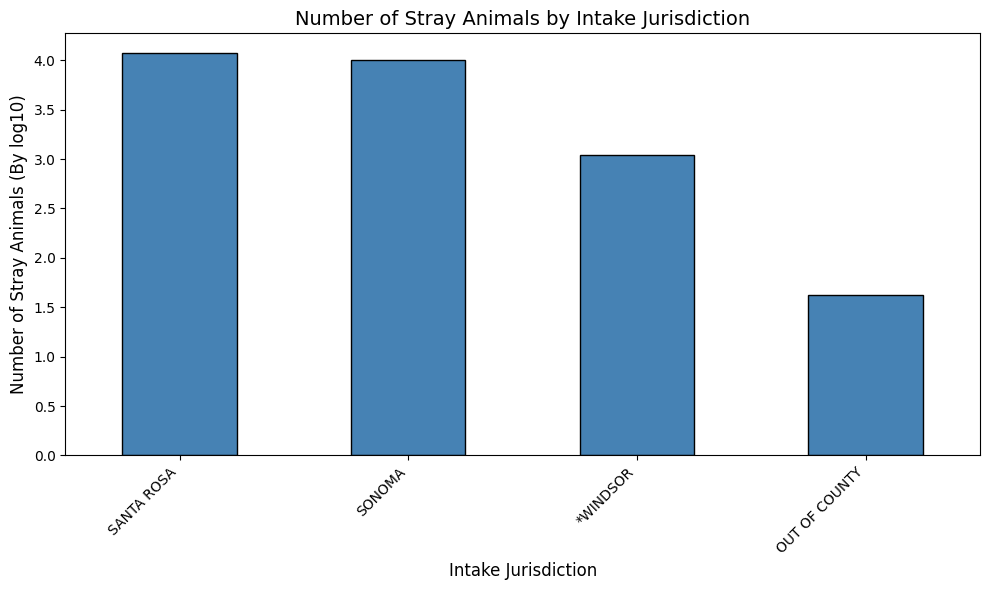

In [ ]:
strays_df = df[df['Intake Type'] == 'STRAY']
stray_count = strays_df['Intake Jurisdiction'].value_counts()
targets = ['SANTA ROSA', 'COUNTY', '*WINDSOR', 'OUT OF COUNTY']
stray_count = stray_count[stray_count.index.isin(targets)]
stray_count = stray_count.rename({'COUNTY': 'SONOMA'})

plt.figure(figsize = (10, 6))
np.log10(stray_count).plot(kind = 'bar', color = 'steelblue', edgecolor = 'black')
plt.title('Number of Stray Animals by Intake Jurisdiction', fontsize = 14)
plt.xlabel('Intake Jurisdiction', fontsize = 12)
plt.ylabel('Number of Stray Animals (By log10)', fontsize = 12)
plt.xticks(rotation = 45, ha = 'right')
plt.tight_layout()
plt.show()

The bar chart illustrates the total number of stray animals originating from each jurisdiction. This indicates that the shelter's resources are primarily utilized by a few specific areas, suggesting that community outreach would be most impactful in these areas. Note: The labels on the y label are by log10.

#2. Where would they likely end up?

Following up on where stray animals originate, it is important to understand where they are placed after leaving the shelter. Analyzing the outcome jurisdictions for strays helps identify which communities are absorbing these animals through adoption, return-to-owner, or transfer processes.

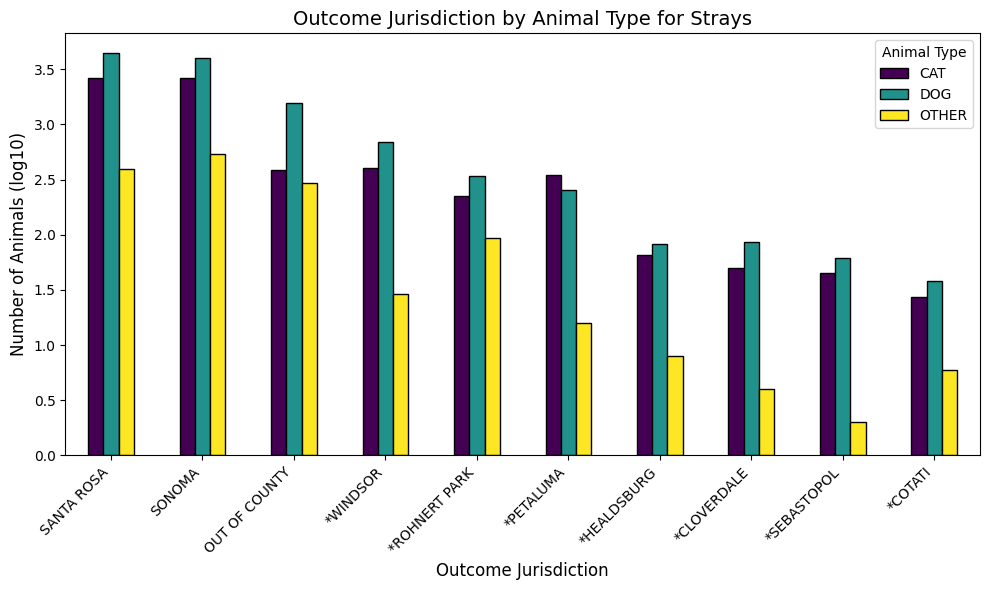

In [ ]:
strays_df = df[df['Intake Type'] == 'STRAY'].copy()
outcome_count = strays_df['Outcome Jurisdiction'].value_counts()

if '*COTATI' in outcome_count.index:
    top_jurisdictions = outcome_count.loc[:'*COTATI'].index
    strays_df = strays_df[strays_df['Outcome Jurisdiction'].isin(top_jurisdictions)]

strays_df['Outcome Jurisdiction'] = strays_df['Outcome Jurisdiction'].replace({'COUNTY': 'SONOMA'})
ct = pd.crosstab(strays_df['Outcome Jurisdiction'], strays_df['Type'])
ct['Total'] = ct.sum(axis = 1)
ct = ct.sort_values(by = 'Total', ascending = False).drop(columns = ['Total'])

log_ct = np.log10(ct + 1)
log_ct.plot(kind = 'bar', figsize = (10, 6), colormap = 'viridis', edgecolor = 'black')

plt.title('Outcome Jurisdiction by Animal Type for Strays', fontsize = 14)
plt.xlabel('Outcome Jurisdiction', fontsize = 12)
plt.ylabel('Number of Animals (log10)', fontsize = 12)
plt.xticks(rotation = 45, ha = 'right')
plt.legend(title = 'Animal Type')
plt.tight_layout()
plt.show()

This bar plot displays the distribution of outcome jurisdictions for animals that entered the shelter as strays. Santa Rosa and Sonoma absorb the majority, but because of log scale, it gives us more room to see. 9 out of 10 jurisdictions tend to adopt dogs more than cats.

#3. What is a stray animal's outcome most likely to be?

Understanding the final disposition of stray animals is critical for evaluating the shelter's life-saving metrics. By analyzing the Outcome Type for strays, shareholders can see the primary ways these animals leave the facility and assess the overall success rate of placing strays into homes.

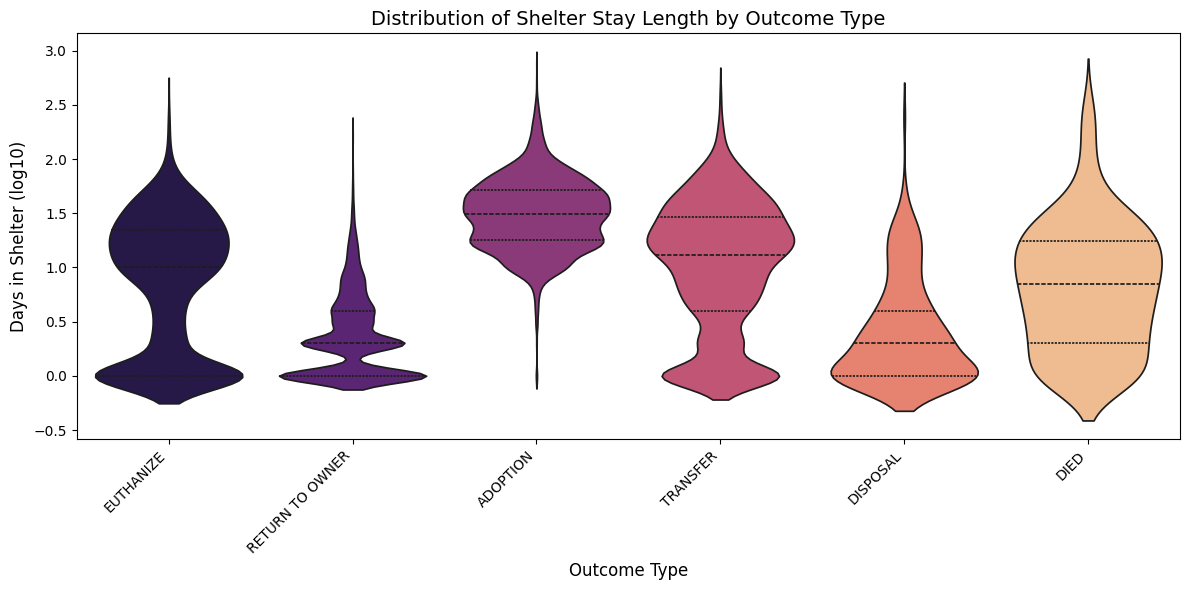

In [ ]:
strays_df = df[df['Intake Type'] == 'STRAY'].copy()
outcome_counts = strays_df['Outcome Type'].value_counts()

if 'RETURN TO OWNER' in outcome_counts.index and 'DIED' in outcome_counts.index:
    target_outcomes = outcome_counts.loc['RETURN TO OWNER':'DIED'].index
    strays_df = strays_df[strays_df['Outcome Type'].isin(target_outcomes)]


strays_df['Days in Shelter (log10)'] = np.log10(strays_df['Days in Shelter'].dropna() + 1)
plt.figure(figsize = (12, 6))
sns.violinplot(
    x = 'Outcome Type',
    y = 'Days in Shelter (log10)',
    data = strays_df,
    hue = 'Outcome Type',
    palette = 'magma',
    inner = 'quartile',
    legend = False
)

plt.title('Distribution of Shelter Stay Length by Outcome Type', fontsize = 14)
plt.xlabel('Outcome Type', fontsize = 12)
plt.ylabel('Days in Shelter (log10)', fontsize = 12)
plt.xticks(rotation = 45, ha='right')
plt.tight_layout()
plt.show()

This bar chart illustrates the most common outcomes for animals brought in as strays. Notice that the two lowest ones are strays that died, and strays that were disposed. What is the difference between the two?

#4. How long do stray animals stay in the shelter?

Understanding the average length of stay for stray animals is a crucial metric for shelter operations. It helps evaluate housing capacity, animal stress levels, and overall operational efficiency. By visualizing the distribution of days spent in the shelter, stakeholders can identify if most strays are moving through the system quickly or if there is a bottleneck.

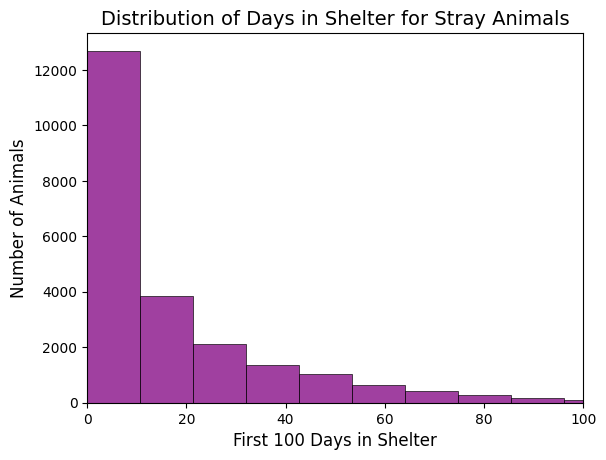

In [ ]:
strays_df = df[df['Intake Type'] == 'STRAY'].copy()
sns.histplot(strays_df['Days in Shelter'], bins = 70, color = 'purple', edgecolor = 'black')
plt.xlim(0,100)
plt.title('Distribution of Days in Shelter for Stray Animals', fontsize = 14)
plt.xlabel('First 100 Days in Shelter', fontsize = 12)
plt.ylabel('Number of Animals', fontsize = 12);


This histogram displays the distribution of the length of stay for stray animals. It appears that most animals are most likely picked up after being put in the shelter.

#5. How does the sterilization status of the animals who enter as strays affect length of stay?

To better understand the sterilization status of incoming stray animals, we can break the data down by sex. By comparing males to neutered males, and females to spayed females, we can clearly see the proportion of animals that require sterilization surgery upon intake.

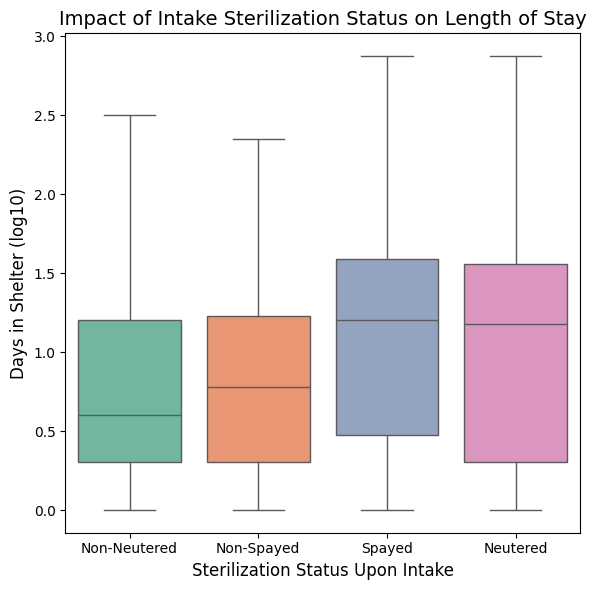

In [ ]:
strays_df = df[df['Intake Type'] == 'STRAY'].copy()
strays_df['Sterilization Status'] = strays_df['Sex'].replace({
    'Male': 'Non-Neutered',
    'Female': 'Non-Spayed'
})

target_status = ['Non-Neutered', 'Neutered', 'Non-Spayed', 'Spayed']
strays_df = strays_df[strays_df['Sterilization Status'].isin(target_status)]
strays_df['Days in Shelter (log10)'] = np.log10(strays_df['Days in Shelter'].dropna() + 1)

plt.figure(figsize = (6, 6))
sns.boxplot(
    x = 'Sterilization Status',
    y = 'Days in Shelter (log10)',
    data = strays_df,
    hue = 'Sterilization Status',
    palette = 'Set2',
    legend = False
)

plt.title('Impact of Intake Sterilization Status on Length of Stay', fontsize = 14)
plt.xlabel('Sterilization Status Upon Intake', fontsize = 12)
plt.ylabel('Days in Shelter (log10)', fontsize = 12)
plt.tight_layout()
plt.show()

This box plot breaks down the sterilization status, and the amount of animals that were either neutured or sprayed, or non-neutered or non-sprayed. Days in shelter is in Log10. Those who aren't neutered or sprayed, are low in quantity than those who are sprayed or neutered.

#6. What is the health status of the stray animals upon intake?

Assessing the medical condition of incoming stray animals is essential for understanding the level of medical care the shelter must provide. By examining the Intake Condition of strays, shelter leadership can evaluate whether incoming animals are healthy or if a large portion arrive injured, ill, or in unknown condition.

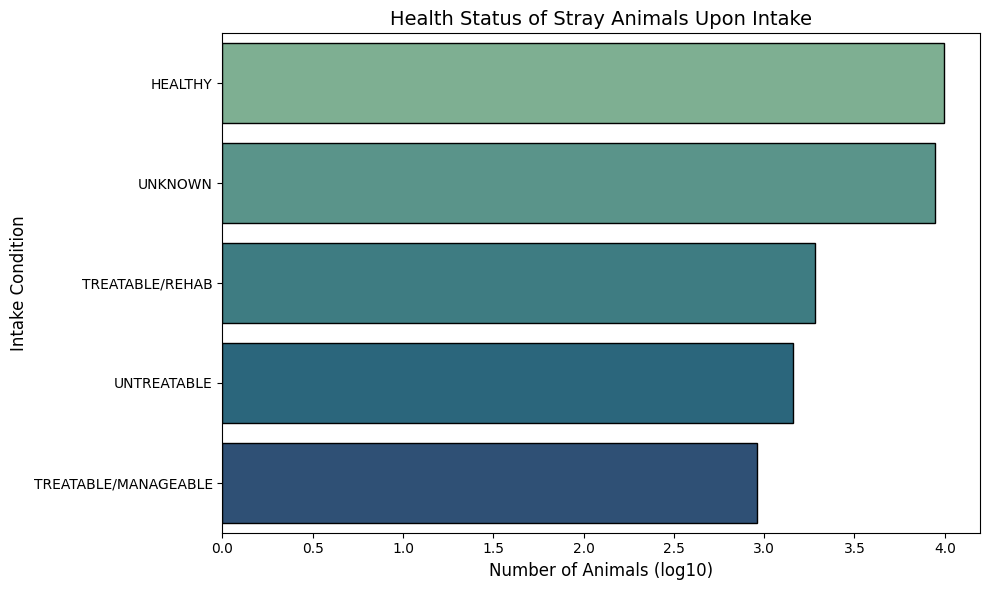

In [ ]:
strays_df = df[df['Intake Type'] == 'STRAY'].copy()
intake_condition_count = strays_df['Intake Condition'].value_counts()
log_condition_count = np.log10(intake_condition_count)

plt.figure(figsize = (10, 6))
sns.barplot(
    x = log_condition_count.values,
    y = log_condition_count.index,
    hue = log_condition_count.index,
    palette = 'crest',
    edgecolor = 'black',
    legend = False
)

plt.title('Health Status of Stray Animals Upon Intake', fontsize = 14)
plt.xlabel('Number of Animals (log10)', fontsize = 12)
plt.ylabel('Intake Condition', fontsize = 12)
plt.tight_layout()
plt.show()

The horizontal bar chart displays the frequency of each health condition recorded when stray animals arrive at the facility. Note that there's two types of tretables.

# 7. What are the most common outcome types per stray animal type?

Here we demonstrate what common outcomes does a stray animal encounters. Surprisingly, the highest value is when a stray animal is returned to the owner (and most of these a dogs) which also have a higer rate of becoming stray dogs as they can get lost, escape from the owner or some other event.

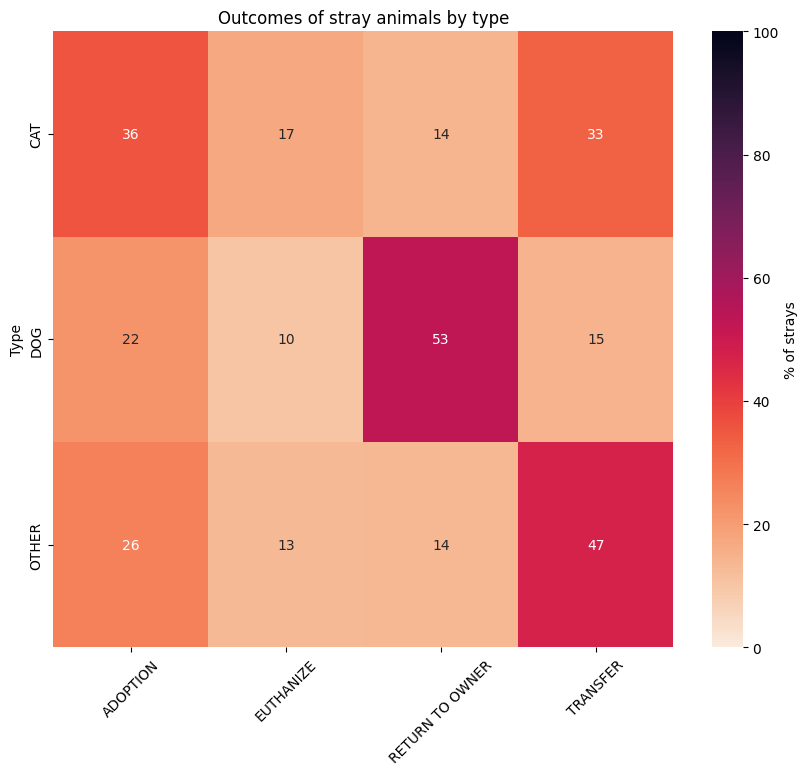

In [ ]:
intake = 'STRAY'
outcome = ['ADOPTION', 'EUTHANIZE', 'RETURN TO OWNER', 'TRANSFER']
d = df[(df['Intake Type'] == intake) & (df['Outcome Type'].isin(outcome))]
plt.figure(figsize = (10, 8))

sns.heatmap(pd.crosstab(d['Type'], d['Outcome Type'], normalize='index') * 100,
            annot=True, fmt='.0f', cmap='rocket_r', vmin=0, vmax=100,
            cbar_kws={'label': '% of strays'})
plt.xticks(rotation=45)
plt.title('Outcomes of stray animals by type')
plt.xlabel('')
plt.show()

# 8. Does size influence adoption rates of stray animals?

Most people make decisions on the size of the animal they are gong to adopt due to various circumstances. In this plot we can see that people rather adopt smaller animals and rates decreases as they increment in size. We noteably see a bigger difference in dogs and others compared to cats, this might be due to cats not being the same size as a Great Dane for example.

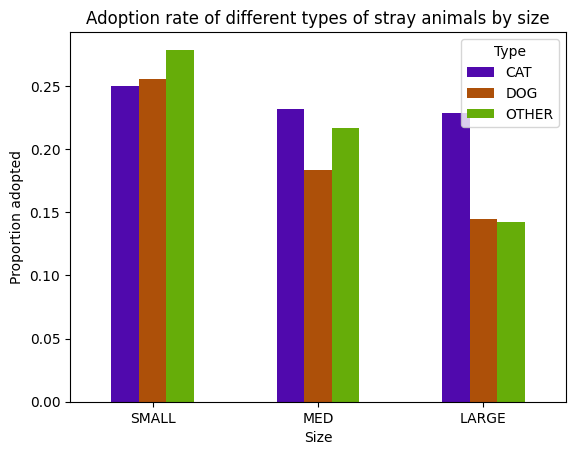

In [ ]:
intake, sizes = 'STRAY', ['SMALL', 'MED', 'LARGE']

d = df[(df['Intake Type'] == intake) & (df['Size'].isin(sizes))]
d = d[d['Type'].isin(['DOG', 'CAT', 'OTHER'])]
colorz=['#5009AD', '#AD5009', '#66AD09']

rate = pd.crosstab(d['Size'], d['Type'], values=(d['Outcome Type'] == 'ADOPTION'), aggfunc='mean').reindex(sizes)

rate.plot.bar(rot=0, color=colorz)
plt.title('Adoption rate of different types of stray animals by size')
plt.ylabel('Proportion adopted')
plt.legend(title='Type');

# 9. What are the average ages of stray animals when they were taken in?

From this graph we can see that for cats, most of them were taken in as kittens showing a median of almost 0 and most kittens are under 2 years old. In contrast, we can see that stray dogs can come in at any life stage but are concentrated in years 1 through 6.

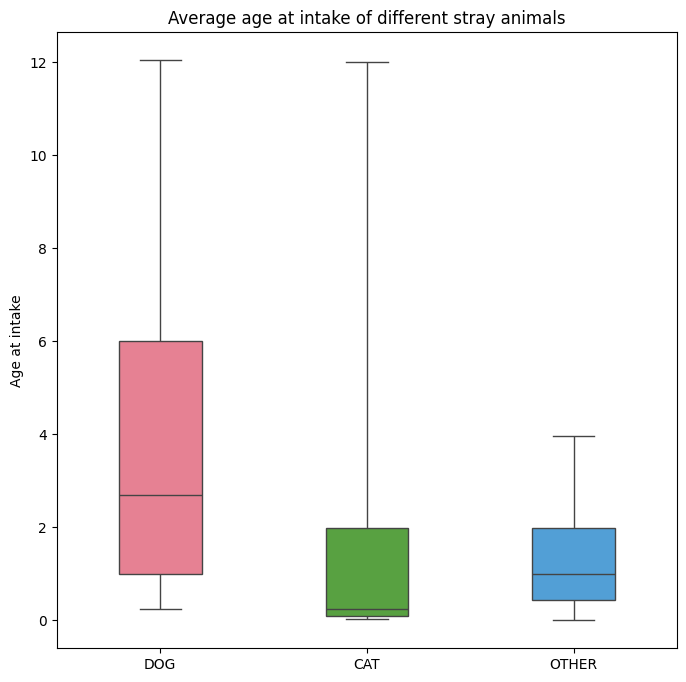

In [ ]:
types = ['DOG', 'CAT', 'OTHER']

d = df[(df['Intake Type'] == 'STRAY' ) & df['age'].between(0,40)]
d = d[d['Type'].isin(types)]
plt.figure(figsize=(8,8))
ax = sns.boxplot(x='Type', y='age', hue='Type' , data=d, palette='husl', width=0.4, showfliers=False, whis=(5,95))
plt.title('Average age at intake of different stray animals')

plt.ylabel('Age at intake')
plt.xlabel('');

# 10. How does intake type vary from animal type?

The main focus of this notebook is to visualize and understand how shelters go on about handling stray animals. With this plot we can see that the vast majority of animals were stray, which gives us a significant amount of data we can explore and analyze.

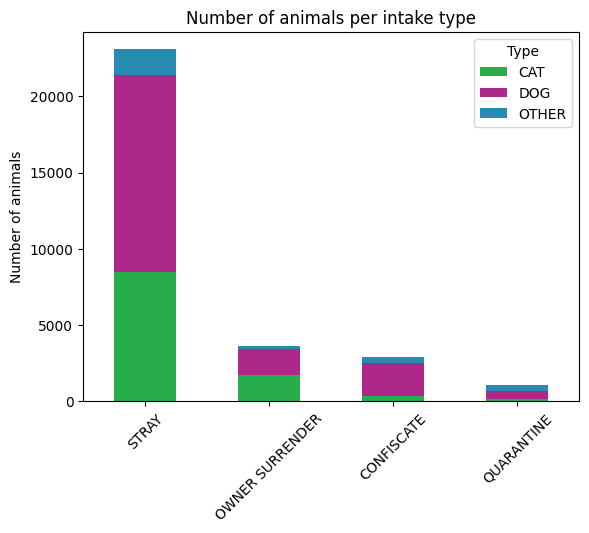

In [ ]:
intake = ['STRAY', 'OWNER SURRENDER', 'CONFISCATE', 'QUARANTINE']

d = df[df['Intake Type'].isin(intake)]

pd.crosstab(d['Intake Type'], d['Type']).loc[intake].plot.bar(stacked=True, rot=45, color=['#27AE4A', '#AE278A', '#278AAE'])
plt.title('Number of animals per intake type')
plt.ylabel('Number of animals')
plt.xlabel('');

## Conclusions

Starting with the location origin of stray animals, we see that a majority of animals come from Santa Rosa and Sonoma, with quite a few from Windsor, and some out of county. Judging from the plot, strays mostly come from Santa Rosa, with Sonoma as a close second. Unsurprisingly, these strays tend to end up in Santa Rosa and Sonoma after their stay at the shelter. However, it is worth noting that many also end up in Windsor or out of county, parallel to the locations in which most originate. When it comes to outcome types of strays, many seem to end up adopted or transferred, and they tend to have longer stays in the shelter in comparison to other outcome types. For how long stray animals stay in the shelter, the positive skew of the histogram reveals that most only stay for 0-10 days. As for how sterilization affects the length of stay at the shelter, animals who are sterilized tend to have a longer stay than those who aren't. However, it is worth noting that there are more animals who are sterilized than those who aren't.



The latter five conclusions were also recorded. Beginning with a look at the general health status of stray animals upon intake. It was found that a majority of the strays entered as healthy, only about 1995 strays were untreatable. Next we look at the outcomes of stray animals. Out of all of the types of animals dogs are most likely to be returned to their owners, while stray cats faced the highest rate of euthanasia. Further we now examine how adoption rates are affected by size and type of the animal. Across all three types of animals small animals are the most likely to be adopted which makes sense as larger animals need larger spaces and more attention time in comparison with smaller dogs which are known to be easier to take care of.
At the time of intake, we notice how age of intake varies from dogs and cats. We see some trends of cats being taken in at a younger age compared to dogs, who are taken in at any point of their lives. Finalizing, for the Sonoma County Shelter we conclude that stray animals were the highest category of intake, followed by the animal being surrender by the owner, confiscated and quarantine due to illness or a fatal disease.
